In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pickle as pkl
import os
import glob
import cartopy as cp
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from matplotlib.colors import ListedColormap, BoundaryNorm
#from plot_ACCLIP_profs import plot_model_overlay, get_ACCLIP_merge_data, get_model_prof_data
import plotter_config as pc
#from get_cbar import get_colorbar

In [2]:
def draw_box(ax, left, right, bot, top, col, thk):
    ax.plot([left, left], [bot, top], color=col, linewidth=thk)
    ax.plot([right, right], [bot, top], color=col, linewidth=thk)
    ax.plot([left, right], [bot, bot], color=col, linewidth=thk)
    ax.plot([left, right], [top, top], color=col, linewidth=thk)    

In [3]:
def make_map_diff_plot(ax, SAVEDIR, model_names, var, prs_lvl, lev_choice, date0, date1, cbaraxes = [0.13,0.05,0.76,0.02], cb_or='horizontal', pct=False, cbar=False, levels=np.arange(-40,40.1,10), map_ASM=False):

    var_lab = pc.var_info[var]['lab']
    var_mod = pc.var_info[var]['mod']
    
    if var[0] == 'X':

        with open('/glade/u/home/wsmith/NudgeComparison_scripts/vars/' + var + '1.pkl', 'rb') as f:
            lon, lat, var_mean1 = pkl.load(f)

        with open('/glade/u/home/wsmith/NudgeComparison_scripts/vars/' + var + '2.pkl', 'rb') as f:
            lon, lat, var_mean2 = pkl.load(f)
    
    else: 
    
        with open(SAVEDIR + model_names[0] + '_' + var + '_AvgMap_' + lev_choice + '_' + date0 + '_' + date1 + '.pkl', 'rb') as f:     # PREVIOUSLY MapData (reader v0)
            var_array1, lvls1, lon, lat, date, datesec = pkl.load(f)
        print(np.shape(var_array1))
        p = list(lvls1).index(prs_lvl)
        #var_mean1 = np.nanmean(np.squeeze(var_array1[:,p,:,:]), axis = 0)*var_mod     # From version 0
        var_mean1 = np.squeeze(var_array1[p,:,:])*var_mod
    
        with open(SAVEDIR + model_names[1] + '_' + var + '_AvgMap_' + lev_choice + '_' + date0 + '_' + date1 + '.pkl', 'rb') as f:     # PREVIOUSLY MapData (reader v0)
            var_array2, lvls2, lon, lat, date, datesec = pkl.load(f)
        p = list(lvls2).index(prs_lvl)
        #var_mean2 = np.nanmean(np.squeeze(var_array2[:,p,:,:]), axis = 0)*var_mod     # From version 0
        var_mean2 = np.squeeze(var_array2[p,:,:])*var_mod

    if pct == False: 
        var_diff = var_mean1 - var_mean2   # Absolute difference
        #levels = np.arange(-10,10.1,1)
        cbar_lab =  var_lab + ' change (' + pc.var_info[var]['unit'] + ')'   
    if pct == True: 
        var_diff = (var_mean1 - var_mean2)*100./var_mean1   # Percent change
        cbar_lab = 'Percent Change'
    
    #cbar_lab =  var_lab + ' Change (%)'


    var_diff_cyc, lon_cyc = cp.util.add_cyclic_point(var_diff, coord=lon)
    
    print(np.min(var_diff), np.max(var_diff))

    #colormap = plt.get_cmap('Blues')
    colormap = plt.get_cmap('coolwarm')
    colormap.set_over([0.6,0.6,0.6])
    #levels = np.arange(cbmin,0.001,-cbmin/10.)
    #levels = [0,1,2,3,5,7,9,12,15,20,25]
    #levels = [-25,-15,-10,-5,-3,-1,0]

    norm = BoundaryNorm(levels, colormap.N)
    
    #levels, colormap, norm = get_colorbar(var, prs_lvl, 0)  # Get colorbar information

    if map_ASM == False: 
        ax.set_ylim([-90,90])
        ax.set_xlim([-180,180])
    else: 
        #ax.set_xlim([105,145])
        #ax.set_ylim([25,45])
        #draw_box(ax, 110, 122, 36, 42, 'gray', 2)
        ax.set_xlim([30,150])
        ax.set_ylim([0,60])

    #con = ax.contourf(lon_cyc, lat, var_diff_cyc, cmap = colormap, levels = levels, norm=norm, extend = 'both', transform=ccrs.PlateCarree())
    con = ax.pcolormesh(lon_cyc, lat, var_diff_cyc, cmap = colormap, norm=norm, transform=ccrs.PlateCarree())
    ax.coastlines()

    if cbar == True: 
        cbaxes = fig.add_axes(cbaraxes)
        cbar = plt.colorbar(con, cax=cbaxes, \
                orientation=cb_or, spacing='uniform',\
                shrink=0.5, extend='both')#, ticks=levels[:-1])  
        cbar.ax.tick_params(labelsize=14)
        cbar.set_label(cbar_lab, fontsize=12)
        

    #GV_OBSROOT = '/glade/work/wsmith/ACCLIP_GV_R1_60SEC_Merge/'
    #GV_FLT_DATES = ['20220730','20220804','20220806','20220807','20220812','20220815','20220816','20220819','20220822','20220823','20220825','20220826','20220829','20220830']
    #ACCLIP_GV_lon = get_ACCLIP_merge_data(GV_OBSROOT, GV_FLT_DATES, 'GGLON') 
    #ACCLIP_GV_lat = get_ACCLIP_merge_data(GV_OBSROOT, GV_FLT_DATES, 'GGLAT')     

    #WB_OBSROOT = '/glade/work/wsmith/ACCLIP_WB57_R1_60SEC_Merge/'
    #WB_FLT_DATES = ['20220802','20220804','20220806','20220812','20220813','20220815','20220816','20220819','20220821','20220823','20220825','20220826','20220829','20220831','20220901']
    #ACCLIP_WB_lon = get_ACCLIP_merge_data(WB_OBSROOT, WB_FLT_DATES, 'G_LONG_MMS') 
    #ACCLIP_WB_lat = get_ACCLIP_merge_data(WB_OBSROOT, WB_FLT_DATES, 'G_LAT_MMS') 

    #ax.scatter(ACCLIP_GV_lon, ACCLIP_GV_lat, s=0.1, color='black')
    #ax.scatter(ACCLIP_WB_lon, ACCLIP_WB_lat, s=0.1, color='gray')
    

In [4]:

SAVEDIR = '/glade/u/home/wsmith/NudgeComparison_scripts/vars/'

model_names = ['2022_E5-strong_h0','2022_M2-strong_h0']

var_strs = ['CO']  
pct = True      # Whether to do percent change

date0 = '2022-05' 
date1 = '2022-09'


(7, 192, 288)
-5.494249998276019 22.234646440967637
(7, 192, 288)
-22.70305499707303 18.488595955469048
(7, 192, 288)
-22.902208503302028 17.308373289190488


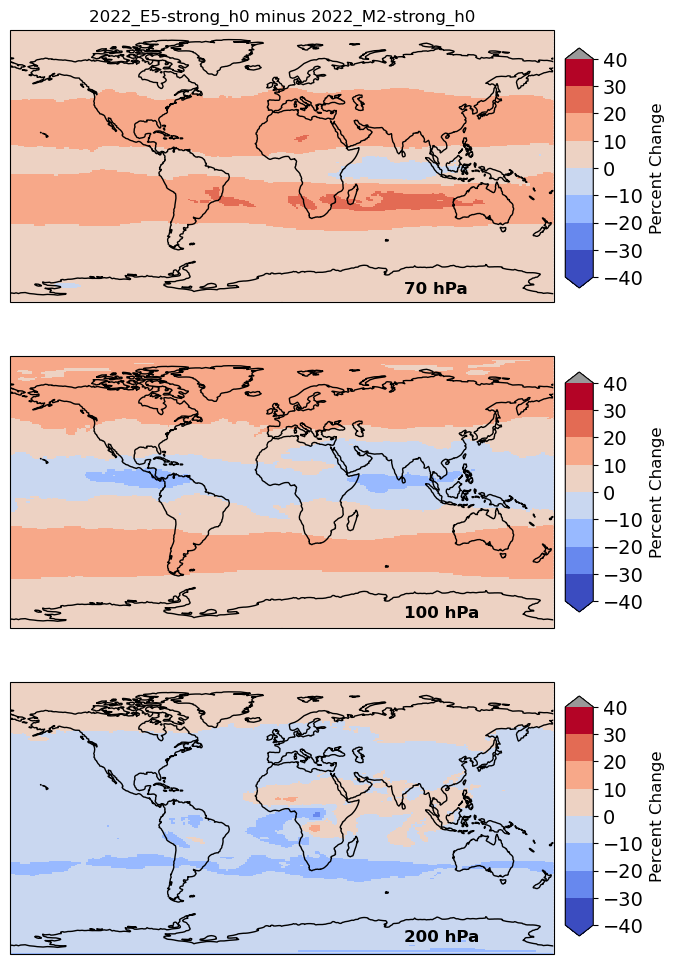

In [5]:

for var_str in var_strs: 

    fig = plt.figure(figsize=(14,12))
    ax1 = fig.add_subplot(311, projection = ccrs.PlateCarree())
    ax2 = fig.add_subplot(312, projection = ccrs.PlateCarree())
    ax3 = fig.add_subplot(313, projection = ccrs.PlateCarree())
    #ax4 = fig.add_subplot(224, projection = ccrs.PlateCarree())

    #make_map_diff_plot(ax1, SAVEDIR, model_names, var_str, 850., 'plev', date0, date1, cbaraxes = [0.715,0.665,0.02,0.2], cb_or='vertical', pct=pct, cbar=True)
    make_map_diff_plot(ax1, SAVEDIR, model_names, var_str,  70., 'plev', date0, date1, cbaraxes = [0.715,0.665,0.02,0.2], cb_or='vertical', pct=pct, cbar=True)
    make_map_diff_plot(ax2, SAVEDIR, model_names, var_str, 100., 'plev', date0, date1, cbaraxes = [0.715,0.395,0.02,0.2], cb_or='vertical', pct=pct, cbar=True)
    make_map_diff_plot(ax3, SAVEDIR, model_names, var_str, 200., 'plev', date0, date1, cbaraxes = [0.715,0.125,0.02,0.2], cb_or='vertical', pct=pct, cbar=True)
    
    plt.figtext(0.6,0.66,'70 hPa', fontsize=12, fontweight='bold')
    plt.figtext(0.6,0.39,'100 hPa', fontsize=12, fontweight='bold')
    plt.figtext(0.6,0.12,'200 hPa', fontsize=12, fontweight='bold')    

    #make_map_diff_plot(ax1, SAVEDIR, model_names, var_str, 200., 'plev', date0, date1, cbaraxes = [0.715,0.665,0.02,0.2], cb_or='vertical', pct=pct)
    #make_map_diff_plot(ax2, SAVEDIR, model_names, var_str, 250., 'plev', date0, date1, cbaraxes = [0.715,0.395,0.02,0.2], cb_or='vertical', pct=pct)
    #make_map_diff_plot(ax3, SAVEDIR, model_names, var_str, 300., 'plev', date0, date1, cbaraxes = [0.715,0.125,0.02,0.2], cb_or='vertical', pct=pct)    
    #plt.figtext(0.6,0.66,'200 hPa', fontsize=12, fontweight='bold')
    #plt.figtext(0.6,0.39,'250 hPa', fontsize=12, fontweight='bold')
    #plt.figtext(0.6,0.12,'300 hPa', fontsize=12, fontweight='bold')        
    

    
    #plt.suptitle(model_names[0] + ' minus ' + model_names[1])
    ax1.set_title(model_names[0] + ' minus ' + model_names[1], fontsize=12)


(7, 192, 288)
-11.086585867397112 19.777368165023088
(7, 192, 288)
-9.693695140661935 21.01913558534008
(7, 192, 288)
-19.006467422105164 14.462267096949804
(7, 192, 288)
-19.762663912583214 12.00190918061785
(7, 192, 288)
-15.990981902403036 22.702441926304786
(7, 192, 288)
-7.558939338922338 24.355036941835873
(7, 192, 288)
-8.97325748760096 17.391707801044202
(7, 192, 288)
-108.64984240052887 43.314693139519704
(7, 192, 288)
-32.52510141255895 19.76895943067148


Text(0.84, 0.12, '(i)')

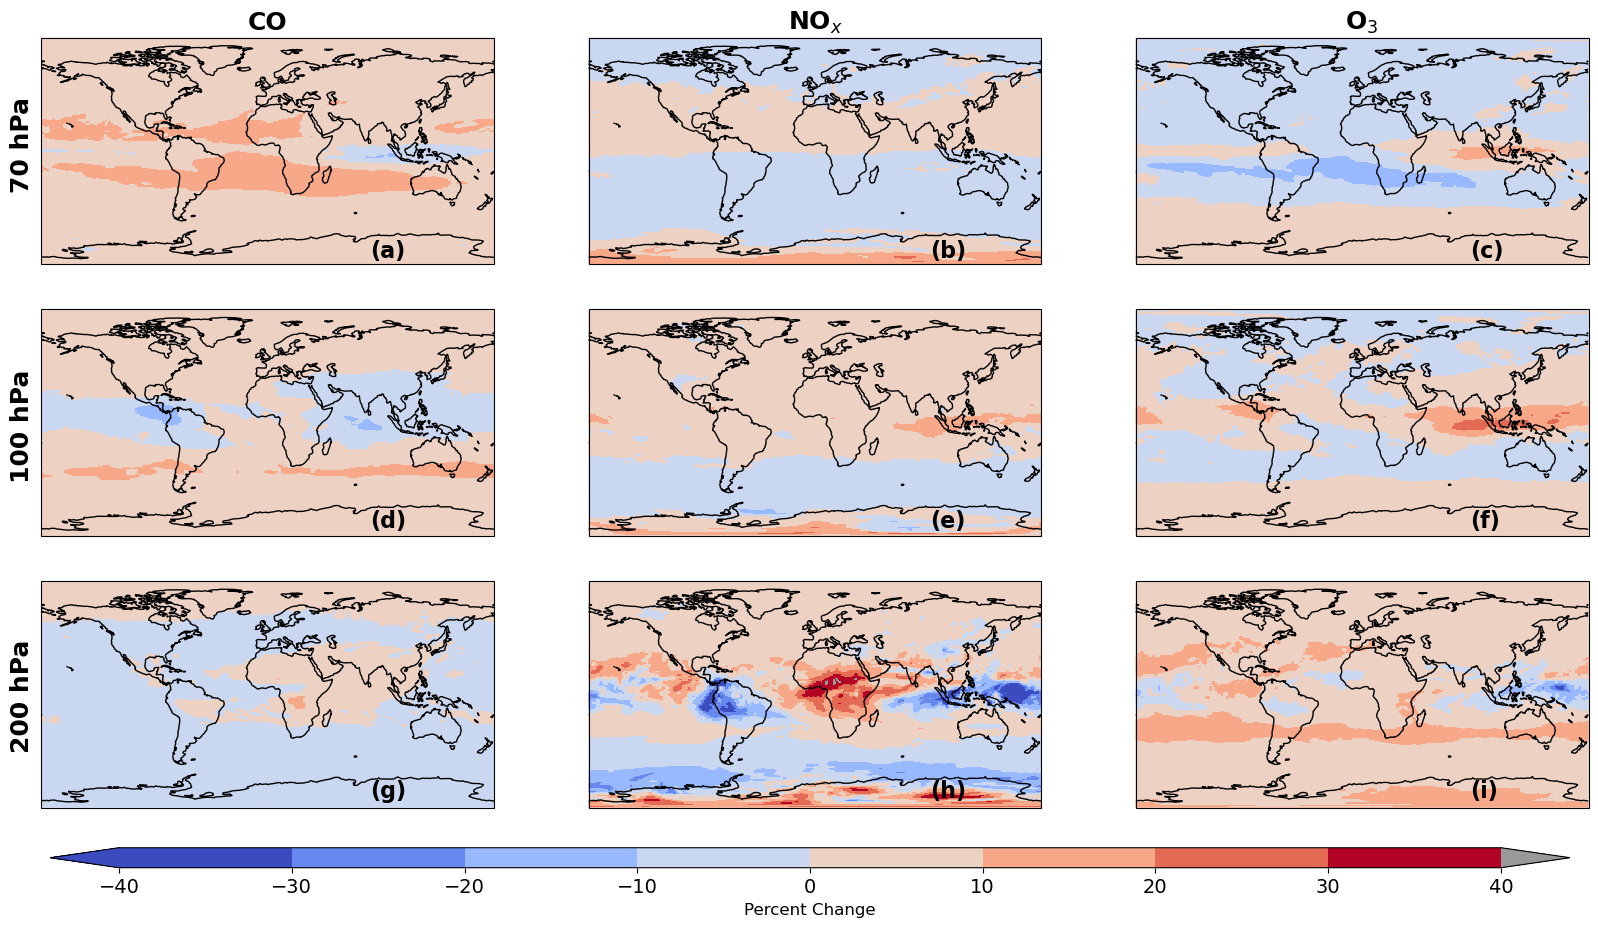

In [6]:

#model_names = ['2022_E5-strong_h0','2022_M2-strong_h0']
model_names = ['2022_E5-weak_h0','2022_M2-weak_h0']
#model_names = ['2022_E5-strong_h0','2022_E5-weak_h0']

date0 = '2022-05' 
date1 = '2022-09'

vars = ['CO','NOx','O3']

fig = plt.figure(figsize=(20,10))
ax1 = fig.add_subplot(331, projection = ccrs.PlateCarree())
ax2 = fig.add_subplot(332, projection = ccrs.PlateCarree())
ax3 = fig.add_subplot(333, projection = ccrs.PlateCarree())
ax4 = fig.add_subplot(334, projection = ccrs.PlateCarree())
ax5 = fig.add_subplot(335, projection = ccrs.PlateCarree())
ax6 = fig.add_subplot(336, projection = ccrs.PlateCarree())
ax7 = fig.add_subplot(337, projection = ccrs.PlateCarree())
ax8 = fig.add_subplot(338, projection = ccrs.PlateCarree())
ax9 = fig.add_subplot(339, projection = ccrs.PlateCarree())

make_map_diff_plot(ax1, SAVEDIR, model_names, vars[0],  70., 'plev', date0, date1, pct=True, cbar=True)
make_map_diff_plot(ax2, SAVEDIR, model_names, vars[1],  70., 'plev', date0, date1, pct=True)
make_map_diff_plot(ax3, SAVEDIR, model_names, vars[2],  70., 'plev', date0, date1, pct=True)

make_map_diff_plot(ax4, SAVEDIR, model_names, vars[0], 100., 'plev', date0, date1, pct=True)
make_map_diff_plot(ax5, SAVEDIR, model_names, vars[1], 100., 'plev', date0, date1, pct=True)
make_map_diff_plot(ax6, SAVEDIR, model_names, vars[2], 100., 'plev', date0, date1, pct=True)

make_map_diff_plot(ax7, SAVEDIR, model_names, vars[0], 200., 'plev', date0, date1, pct=True)
make_map_diff_plot(ax8, SAVEDIR, model_names, vars[1], 200., 'plev', date0, date1, pct=True)
make_map_diff_plot(ax9, SAVEDIR, model_names, vars[2], 200., 'plev', date0, date1, pct=True)

ax1.set_title(pc.var_info[vars[0]]['lab'], fontsize=18, fontweight='bold')
ax2.set_title(pc.var_info[vars[1]]['lab'], fontsize=18, fontweight='bold')
ax3.set_title(pc.var_info[vars[2]]['lab'], fontsize=18, fontweight='bold')

plt.figtext(0.11,0.73,'70 hPa', fontsize=18, rotation=90, fontweight='bold')
plt.figtext(0.11,0.44,'100 hPa', fontsize=18, rotation=90, fontweight='bold')
plt.figtext(0.11,0.17,'200 hPa', fontsize=18, rotation=90, fontweight='bold')  

plt.figtext(0.29,0.66,'(a)', fontsize=16, fontweight='bold')
plt.figtext(0.57,0.66,'(b)', fontsize=16, fontweight='bold')
plt.figtext(0.84,0.66,'(c)', fontsize=16, fontweight='bold')
plt.figtext(0.29,0.39,'(d)', fontsize=16, fontweight='bold')
plt.figtext(0.57,0.39,'(e)', fontsize=16, fontweight='bold')
plt.figtext(0.84,0.39,'(f)', fontsize=16, fontweight='bold')
plt.figtext(0.29,0.12,'(g)', fontsize=16, fontweight='bold')
plt.figtext(0.57,0.12,'(h)', fontsize=16, fontweight='bold')
plt.figtext(0.84,0.12,'(i)', fontsize=16, fontweight='bold')

#plt.savefig('/glade/u/home/wsmith/NudgeComparison_scripts/plots/Figure3.png')
#plt.savefig('/glade/u/home/wsmith/NudgeComparison_scripts/plots/Figure3.pdf')


(7, 192, 288)
nan nan
(7, 192, 288)
-12.242970239106029 0.4064520349918439


/glade/derecho/scratch/wsmith/tmp/ipykernel_52701/1070107313.py:34: RuntimeWarning: divide by zero encountered in divide
  var_diff = (var_mean1 - var_mean2)*100./var_mean1   # Percent change
/glade/derecho/scratch/wsmith/tmp/ipykernel_52701/1070107313.py:34: RuntimeWarning: invalid value encountered in divide
  var_diff = (var_mean1 - var_mean2)*100./var_mean1   # Percent change


(7, 192, 288)
nan nan
(7, 192, 288)
-0.10921957670564097 0.05748134516539949


/glade/derecho/scratch/wsmith/tmp/ipykernel_52701/1070107313.py:34: RuntimeWarning: divide by zero encountered in divide
  var_diff = (var_mean1 - var_mean2)*100./var_mean1   # Percent change
/glade/derecho/scratch/wsmith/tmp/ipykernel_52701/1070107313.py:34: RuntimeWarning: invalid value encountered in divide
  var_diff = (var_mean1 - var_mean2)*100./var_mean1   # Percent change


Text(0.11, 0.14, 'E5-strong vs E5-weak')

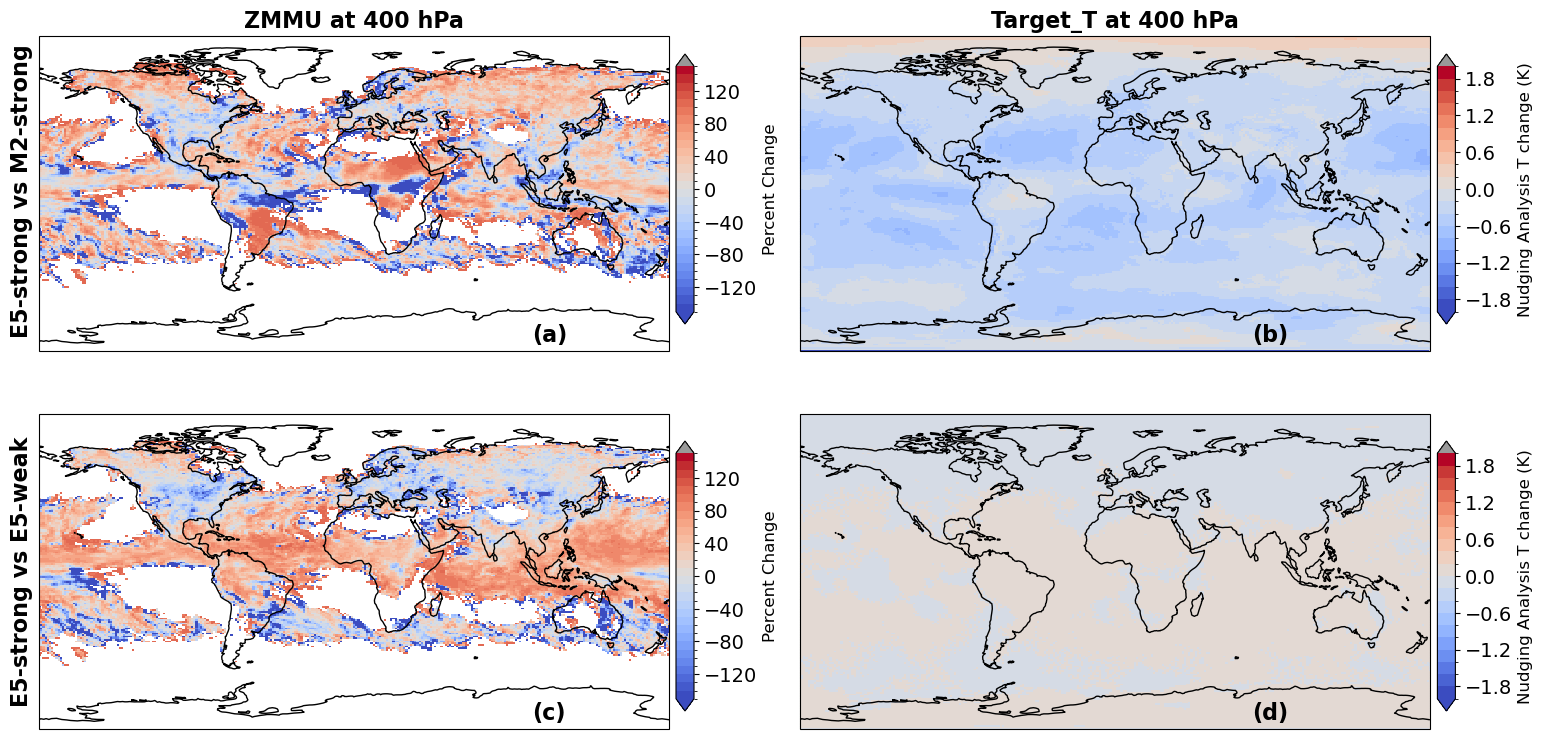

In [7]:

# For Figure S1
vars = ['ZMMU','Target_T','CAPE']
levs = [400.,400.,0.]

fig = plt.figure(figsize=(18,9))
ax1 = fig.add_subplot(221, projection = ccrs.PlateCarree())
ax2 = fig.add_subplot(222, projection = ccrs.PlateCarree())
ax3 = fig.add_subplot(223, projection = ccrs.PlateCarree())
ax4 = fig.add_subplot(224, projection = ccrs.PlateCarree())

make_map_diff_plot(ax1, SAVEDIR, ['2022_E5-strong_h0','2022_M2-strong_h0'], vars[0], levs[0], 'plev', '2022-05', '2022-09', cbaraxes = [0.48,0.56,0.01,0.3], cb_or='vertical', pct=True, cbar=True, levels=np.arange(-150,150.1,10))
make_map_diff_plot(ax2, SAVEDIR, ['2022_E5-strong','2022_M2-strong'], vars[1], levs[1], 'plev', '2022-05-01', '2022-09-30', cbaraxes = [0.903,0.56,0.01,0.3], cb_or='vertical', pct=False, cbar=True, levels=np.arange(-2,2.01,0.2))

make_map_diff_plot(ax3, SAVEDIR, ['2022_E5-strong_h0','2022_E5-weak_h0'], vars[0], levs[0], 'plev', '2022-05', '2022-09', cbaraxes = [0.48,0.13,0.01,0.3], cb_or='vertical', pct=True, cbar=True, levels=np.arange(-150,150.1,10))
make_map_diff_plot(ax4, SAVEDIR, ['2022_E5-strong','2022_E5-weak'], vars[1], levs[1], 'plev', '2022-05-01', '2022-09-30', cbaraxes = [0.903,0.13,0.01,0.3], cb_or='vertical', pct=False, cbar=True, levels=np.arange(-2,2.01,0.2))

plt.figtext(0.4,0.54,'(a)', fontsize=16, fontweight='bold')
plt.figtext(0.8,0.54,'(b)', fontsize=16, fontweight='bold')
plt.figtext(0.4,0.12,'(c)', fontsize=16, fontweight='bold')
plt.figtext(0.8,0.12,'(d)', fontsize=16, fontweight='bold')

ax1.set_title(vars[0] + ' at ' + str(int(levs[0])) + ' hPa', fontsize=16, fontweight='bold')
ax2.set_title(vars[1] + ' at ' + str(int(levs[1])) + ' hPa', fontsize=16, fontweight='bold')

plt.figtext(0.11,0.55,'E5-strong vs M2-strong', fontsize=16, rotation=90, fontweight='bold')
plt.figtext(0.11,0.14,'E5-strong vs E5-weak', fontsize=16, rotation=90, fontweight='bold')


(1, 192, 288)
-1496.1317 100.0
(7, 192, 288)
-1420.216104154627 97.81346582456351
-24.943174004752837 22.54929388246943
(7, 192, 288)
-158.23147290135682 36.81778052671761
(7, 192, 288)
-2540.123398724177 91.57025868112304
(7, 192, 288)
-1779.4653495051643 97.74635876018345


Text(0.5, 1.0, '(f) CO_CHML Difference on 2022-08-18 at 200 hPa')

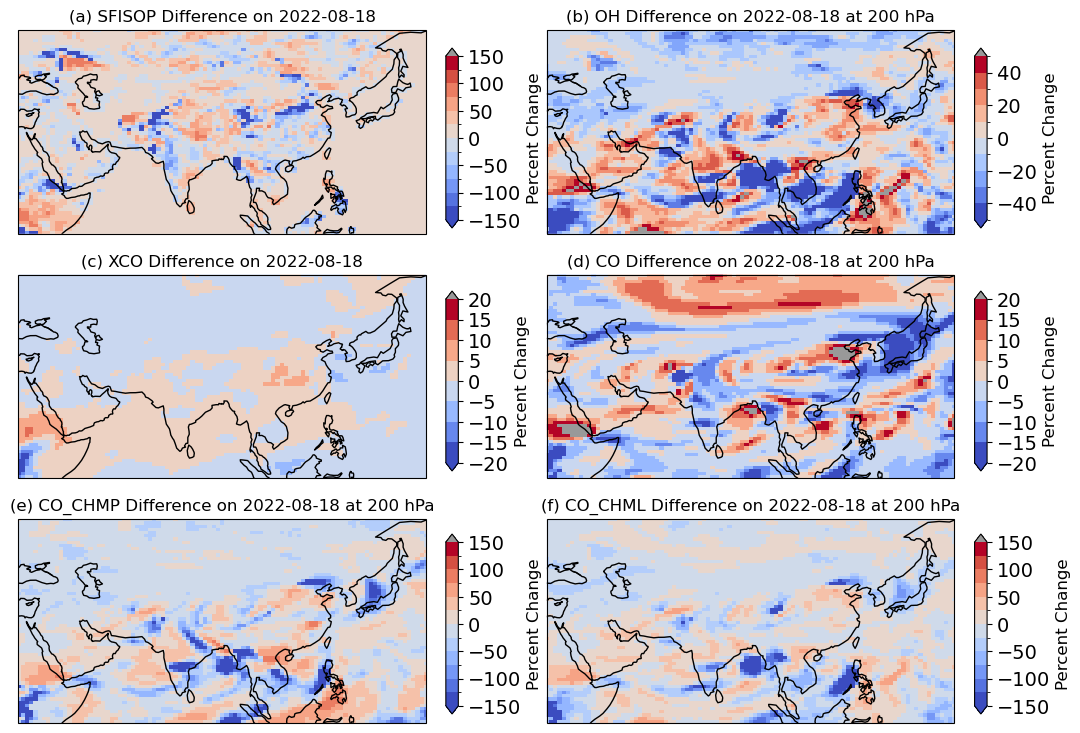

In [8]:

vars = ['SFISOP','OH','XCO','CO','CO_CHMP','CO_CHML']
levs = [0,200,0,200,200,200]

date0 = '2022-08-18'  # Keep this the same for date1

fig = plt.figure(figsize=(12.5,9))
ax1 = fig.add_subplot(321, projection = ccrs.PlateCarree())
ax2 = fig.add_subplot(322, projection = ccrs.PlateCarree())
ax3 = fig.add_subplot(323, projection = ccrs.PlateCarree())
ax4 = fig.add_subplot(324, projection = ccrs.PlateCarree())
ax5 = fig.add_subplot(325, projection = ccrs.PlateCarree())
ax6 = fig.add_subplot(326, projection = ccrs.PlateCarree())

make_map_diff_plot(ax1, SAVEDIR, ['2022_E5-strong','2022_M2-strong'], vars[0], levs[0], 'plev', date0, date0, cbaraxes = [0.48,0.66,0.01,0.2], cb_or='vertical', pct=True, cbar=True, levels=np.arange(-150,150.1,25), map_ASM=True)
make_map_diff_plot(ax2, SAVEDIR, ['2022_E5-strong','2022_M2-strong'], vars[1], levs[1], 'plev', date0, date0, cbaraxes = [0.903,0.66,0.01,0.2], cb_or='vertical', pct=True, cbar=True, levels=np.arange(-50,50.1,10), map_ASM=True)
make_map_diff_plot(ax3, SAVEDIR, ['2022_E5-strong','2022_M2-strong'], vars[2], levs[2], 'plev', date0, date0, cbaraxes = [0.48,0.39,0.01,0.2], cb_or='vertical', pct=True, cbar=True, levels=np.arange(-20,20.1,5), map_ASM=True)
make_map_diff_plot(ax4, SAVEDIR, ['2022_E5-strong','2022_M2-strong'], vars[3], levs[3], 'plev', date0, date0, cbaraxes = [0.903,0.39,0.01,0.2], cb_or='vertical', pct=True, cbar=True, levels=np.arange(-20,20.1,5), map_ASM=True)
make_map_diff_plot(ax5, SAVEDIR, ['2022_E5-strong','2022_M2-strong'], vars[4], levs[4], 'plev', date0, date0, cbaraxes = [0.48,0.12,0.01,0.2], cb_or='vertical', pct=True, cbar=True, levels=np.arange(-150,150.1,25), map_ASM=True)
make_map_diff_plot(ax6, SAVEDIR, ['2022_E5-strong','2022_M2-strong'], vars[5], levs[5], 'plev', date0, date0, cbaraxes = [0.903,0.12,0.01,0.2], cb_or='vertical', pct=True, cbar=True, levels=np.arange(-150,150.1,25), map_ASM=True)

ax1.set_title('(a) ' + vars[0] + ' Difference on ' + date0) # + ' at ' + str(levs[0]) + ' hPa')
ax2.set_title('(b) ' + vars[1] + ' Difference on ' + date0 + ' at ' + str(levs[1]) + ' hPa')
ax3.set_title('(c) ' + vars[2] + ' Difference on ' + date0)
ax4.set_title('(d) ' + vars[3] + ' Difference on ' + date0 + ' at ' + str(levs[3]) + ' hPa')
ax5.set_title('(e) ' + vars[4] + ' Difference on ' + date0 + ' at ' + str(levs[4]) + ' hPa')
ax6.set_title('(f) ' + vars[5] + ' Difference on ' + date0 + ' at ' + str(levs[5]) + ' hPa')


(7, 192, 288)
-32.368862615768116 8.35282398383241
-24.943174004752837 22.54929388246943
(7, 192, 288)
-214.17382054284036 24.762891015658976
-17.075330959788925 46.806756943418144
(7, 192, 288)
-284.9575266644827 54.609847696895564
(1, 192, 288)
-60276.215 100.00001
(7, 192, 288)
-259.2597765468641 23.97885759966748
(1, 192, 288)
-167.84547 100.0


Text(0.5, 1.0, '(h) SFISOP Difference on 2022-08')

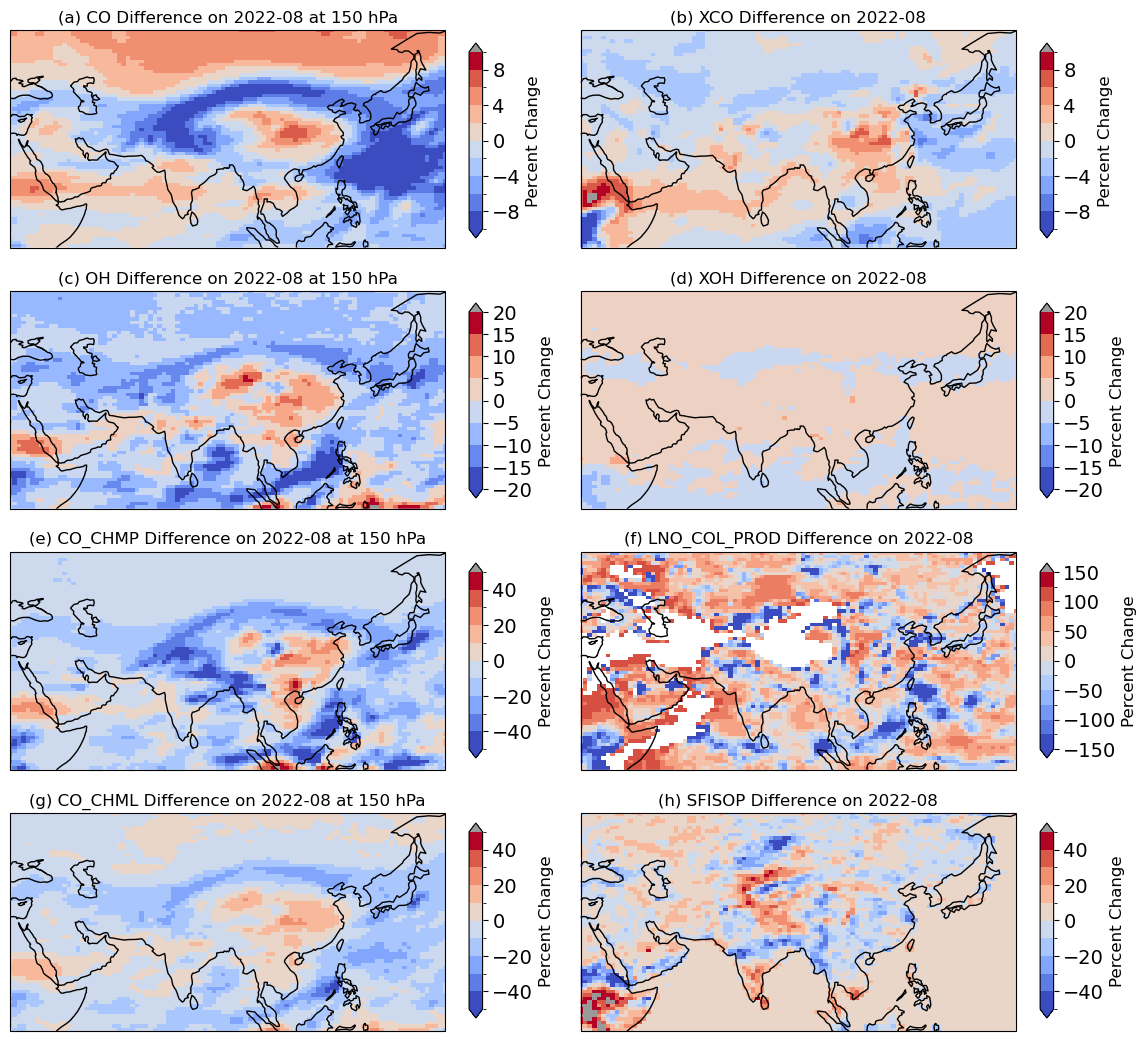

In [23]:

vars = ['CO','XCO','OH','XOH','CO_CHMP','LNO_COL_PROD','CO_CHML','SFISOP']
levs = [150,0,150,0,150,0,150,0]

#vars = ['XCO','CO','CO','CO','CO_CHMP','CO_CHML']
#levs = [0,100,200,400,200,200]

date0 = '2022-08'  # Keep this the same for date1

fig = plt.figure(figsize=(13.5,13))
ax1 = fig.add_subplot(421, projection = ccrs.PlateCarree())
ax2 = fig.add_subplot(422, projection = ccrs.PlateCarree())
ax3 = fig.add_subplot(423, projection = ccrs.PlateCarree())
ax4 = fig.add_subplot(424, projection = ccrs.PlateCarree())
ax5 = fig.add_subplot(425, projection = ccrs.PlateCarree())
ax6 = fig.add_subplot(426, projection = ccrs.PlateCarree())
ax7 = fig.add_subplot(427, projection = ccrs.PlateCarree())
ax8 = fig.add_subplot(428, projection = ccrs.PlateCarree())

make_map_diff_plot(ax1, SAVEDIR, ['2022_E5-strong_h0','2022_M2-strong_h0'], vars[0], levs[0], 'plev', date0, date0, cbaraxes = [0.48,0.72,0.01,0.15], cb_or='vertical', pct=True, cbar=True, levels=np.arange(-10,10.1,2), map_ASM=True)
make_map_diff_plot(ax2, SAVEDIR, ['2022_E5-strong_h0','2022_M2-strong_h0'], vars[1], levs[1], 'plev', date0, date0, cbaraxes = [0.903,0.72,0.01,0.15], cb_or='vertical', pct=True, cbar=True, levels=np.arange(-10,10.1,2), map_ASM=True)
make_map_diff_plot(ax3, SAVEDIR, ['2022_E5-strong_h0','2022_M2-strong_h0'], vars[2], levs[2], 'plev', date0, date0, cbaraxes = [0.48,0.52,0.01,0.15], cb_or='vertical', pct=True, cbar=True, levels=np.arange(-20,20.1,5), map_ASM=True)
make_map_diff_plot(ax4, SAVEDIR, ['2022_E5-strong_h0','2022_M2-strong_h0'], vars[3], levs[3], 'plev', date0, date0, cbaraxes = [0.903,0.52,0.01,0.15], cb_or='vertical', pct=True, cbar=True, levels=np.arange(-20,20.1,5), map_ASM=True)
make_map_diff_plot(ax5, SAVEDIR, ['2022_E5-strong_h0','2022_M2-strong_h0'], vars[4], levs[4], 'plev', date0, date0, cbaraxes = [0.48,0.32,0.01,0.15], cb_or='vertical', pct=True, cbar=True, levels=np.arange(-50,50.1,10), map_ASM=True)
make_map_diff_plot(ax6, SAVEDIR, ['2022_E5-strong_h0','2022_M2-strong_h0'], vars[5], levs[5], 'plev', date0, date0, cbaraxes = [0.903,0.32,0.01,0.15], cb_or='vertical', pct=True, cbar=True, levels=np.arange(-150,150.1,25), map_ASM=True)
make_map_diff_plot(ax7, SAVEDIR, ['2022_E5-strong_h0','2022_M2-strong_h0'], vars[6], levs[6], 'plev', date0, date0, cbaraxes = [0.48,0.12,0.01,0.15], cb_or='vertical', pct=True, cbar=True, levels=np.arange(-50,50.1,10), map_ASM=True)
make_map_diff_plot(ax8, SAVEDIR, ['2022_E5-strong_h0','2022_M2-strong_h0'], vars[7], levs[7], 'plev', date0, date0, cbaraxes = [0.903,0.12,0.01,0.15], cb_or='vertical', pct=True, cbar=True, levels=np.arange(-50,50.1,10), map_ASM=True)

ax1.set_title('(a) ' + vars[0] + ' Difference on ' + date0 + ' at ' + str(levs[0]) + ' hPa')
ax2.set_title('(b) ' + vars[1] + ' Difference on ' + date0) # + ' at ' + str(levs[1]) + ' hPa')
ax3.set_title('(c) ' + vars[2] + ' Difference on ' + date0 + ' at ' + str(levs[2]) + ' hPa')
ax4.set_title('(d) ' + vars[3] + ' Difference on ' + date0) # + ' at ' + str(levs[3]) + ' hPa')
ax5.set_title('(e) ' + vars[4] + ' Difference on ' + date0 + ' at ' + str(levs[4]) + ' hPa')
ax6.set_title('(f) ' + vars[5] + ' Difference on ' + date0)# + ' at ' + str(levs[5]) + ' hPa')
ax7.set_title('(g) ' + vars[6] + ' Difference on ' + date0 + ' at ' + str(levs[6]) + ' hPa')
ax8.set_title('(h) ' + vars[7] + ' Difference on ' + date0) # + ' at ' + str(levs[1]) + ' hPa')


(7, 192, 288)
-61.0154087210946 35.44469660003613


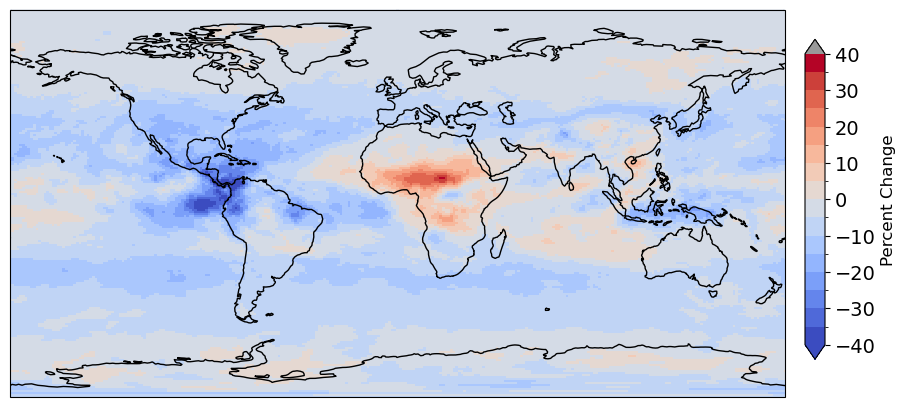

In [10]:

fig = plt.figure(figsize=(10,8))
ax1 = fig.add_subplot(111, projection = ccrs.PlateCarree())

make_map_diff_plot(ax1, SAVEDIR, ['2022_E5-strong_h0','2022_M2-strong_h0'], 'CO_CHML', 150., 'plev', '2022-05', '2022-09', cbaraxes = [0.92,0.3,0.02,0.4], cb_or='vertical', pct=True, cbar=True, levels=np.arange(-40,40.1,5))
